# 11 — v17 : où le pooling spatial regarde

v17 empile deux softmax (12 têtes chacun), plus un BiLSTM sur la profondeur :

1. **coupe** (`attn_score` sur GAP + résidu LSTM) — quelle image parmi 72 tokens (notebook 10) ;
2. **spatial** (`spatial_score`) — où dans cette coupe, grille **14×14** (~16 px).

Les overlays superposent une **heatmap jet** (CAM 14×14 upsamplee en bilinear) sur la coupe IRM. Un blob localisé = tête piquée ; un voile uniforme = encore un GAP. Les PNG sont dans `spatial_inspect/overlays/`.

`Neff` : 196 = GAP, ~80–140 = un peu piqué, &lt; 80 = une poignée de cases.

Défaut : **full-train v17** (`v17_crop130v1`), **gold 58**. Le CAM moyen et la table se rechargent depuis le disque ; les overlays aussi s’ils ont déjà été écrits.

```text
python -X utf8 -m src.infer.inspect_spatial --config configs/kneenet_v17_crop130.yaml --workers 0
```


In [25]:
from __future__ import annotations

import json
import os
import sys
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.infer.inspect_spatial import (
    load_config, peakiness_table, plot_mean_cams, plot_same_slice,
    plot_top_slices, run,
)

CONFIG = ROOT / "configs" / "kneenet_v17_crop130.yaml"
# CONFIG = ROOT / "configs" / "kneenet_v17_crop130_subset.yaml"  # 25 % train
FORCE = False
SPLIT = "gold"       # 58 études, labels vrais
MAX_STUDIES = None
N_EXAMPLES = 6

cfg = load_config(str(CONFIG))
OUT = ROOT / "checkpoints" / cfg["run_name"] / "spatial_inspect"
CKPT = ROOT / "checkpoints" / cfg["run_name"] / "best.pt"
if not CKPT.exists():
    CKPT = ROOT / "checkpoints" / cfg["run_name"] / "last.pt"
print("config", CONFIG.name)
print("ckpt  ", CKPT, "exists", CKPT.exists())
print("out   ", OUT)


config kneenet_v17_crop130.yaml
ckpt   c:\Users\sulta\Documents\RSNA-comp\checkpoints\v17_crop130v1\best.pt exists True
out    c:\Users\sulta\Documents\RSNA-comp\checkpoints\v17_crop130v1\spatial_inspect


In [26]:
import torch

from src.data.dataset_npz import PLANES

summary_path = OUT / "summary.json"
npz_path = OUT / "spatial_agg.npz"
device = "cuda" if torch.cuda.is_available() else "cpu"

if summary_path.exists() and npz_path.exists() and not FORCE:
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    cam = np.load(npz_path)["mean_cam"]
    n_series = cam.shape[0]
    agg = {
        "n_studies": summary["n_studies"],
        "targets": summary["targets"],
        "planes": list(PLANES)[:n_series],
        "mean_cam": cam,
        "mean_entropy": np.asarray(summary["mean_entropy"]),
        "mean_maxp": np.asarray(summary["mean_maxp"]),
        "neff": np.asarray(summary["neff"]),
        "examples": [],
        "pos_examples": {},
    }
    print("chargé", summary_path)
else:
    packed = run(
        cfg, CKPT, SPLIT, OUT, device,
        batch_size=int(cfg.get("batch_size") or 4),
        num_workers=0,
        max_studies=MAX_STUDIES,
        n_examples=N_EXAMPLES,
    )
    summary, agg = packed["summary"], packed["agg"]

print(
    f"{summary['model']}  epoch {summary['epoch']}  "
    f"val AUC {summary['val_macro_auc']}  "
    f"{summary['split']} n={agg['n_studies']}"
)


chargé c:\Users\sulta\Documents\RSNA-comp\checkpoints\v17_crop130v1\spatial_inspect\summary.json
kneenet_v17  epoch 12  val AUC 0.8731099414879878  gold n=58


## Est-ce que le 14×14 s’est piqué ?

Entropie et `Neff` **pondérés par l’attention-coupe** : on ne juge le CAM que sur les slices que la tête utilise vraiment. Uniforme 14×14 = `entropy log(196) ≈ 5.28`, `Neff 196`.


In [27]:
tbl = peakiness_table(agg)
uniforme = int(summary.get("uniform_n") or np.prod(agg["mean_cam"].shape[-2:]))
uniform_entropy = float(summary.get("uniform_entropy") or np.log(max(uniforme, 1)))
gh, gw = agg["mean_cam"].shape[-2:]
display(tbl.style.format({
    "entropy": "{:.2f}",
    "neff": "{:.1f}",
    "max_p": "{:.1%}",
    "uniforme": "{:.0f}",
}))
print(f"uniforme {gh}×{gw} : entropy={uniform_entropy:.2f}  Neff={uniforme}")
n_gap = int((tbl.neff > 0.70 * uniforme).sum())
n_peak = int((tbl.neff <= 0.40 * uniforme).sum())
print(
    f"têtes encore GAP-like (Neff>{0.70 * uniforme:.0f}) : {n_gap}/12   "
    f"piquées (Neff≤{0.40 * uniforme:.0f}) : {n_peak}/12"
)


,target,entropy,neff,max_p,uniforme,lecture
0,ACL,4.55,94.8,8.8%,196,un peu pique
1,MCL,4.87,129.8,4.4%,196,un peu pique
2,Medial Meniscus,4.75,115.4,6.1%,196,un peu pique
3,Lateral Meniscus,4.86,128.7,4.6%,196,un peu pique
4,Medial OA,4.64,103.9,7.3%,196,un peu pique
5,Lateral OA,4.89,133.2,4.5%,196,un peu pique
6,PF OA,4.43,83.8,10.1%,196,un peu pique
7,Effusion,3.29,26.8,25.2%,196,pique
8,Synovitis,4.88,131.7,4.8%,196,un peu pique
9,Baker's,4.43,83.7,10.6%,196,un peu pique


uniforme 14×14 : entropy=5.28  Neff=196
têtes encore GAP-like (Neff>137) : 0/12   piquées (Neff≤78) : 1/12


## CAM moyen par plan et par cible

Heatmap 14×14 (jet). Un blob **en bas / au bord** de la grille, surtout fracture / contusion, est le même signal que la coupe 0 du notebook 10 (raccourci FOV). Un blob **central** (Baker, MCL, épanchement) est plus anatomique. Une case ≈ 16 px (vs 32 px en v14).


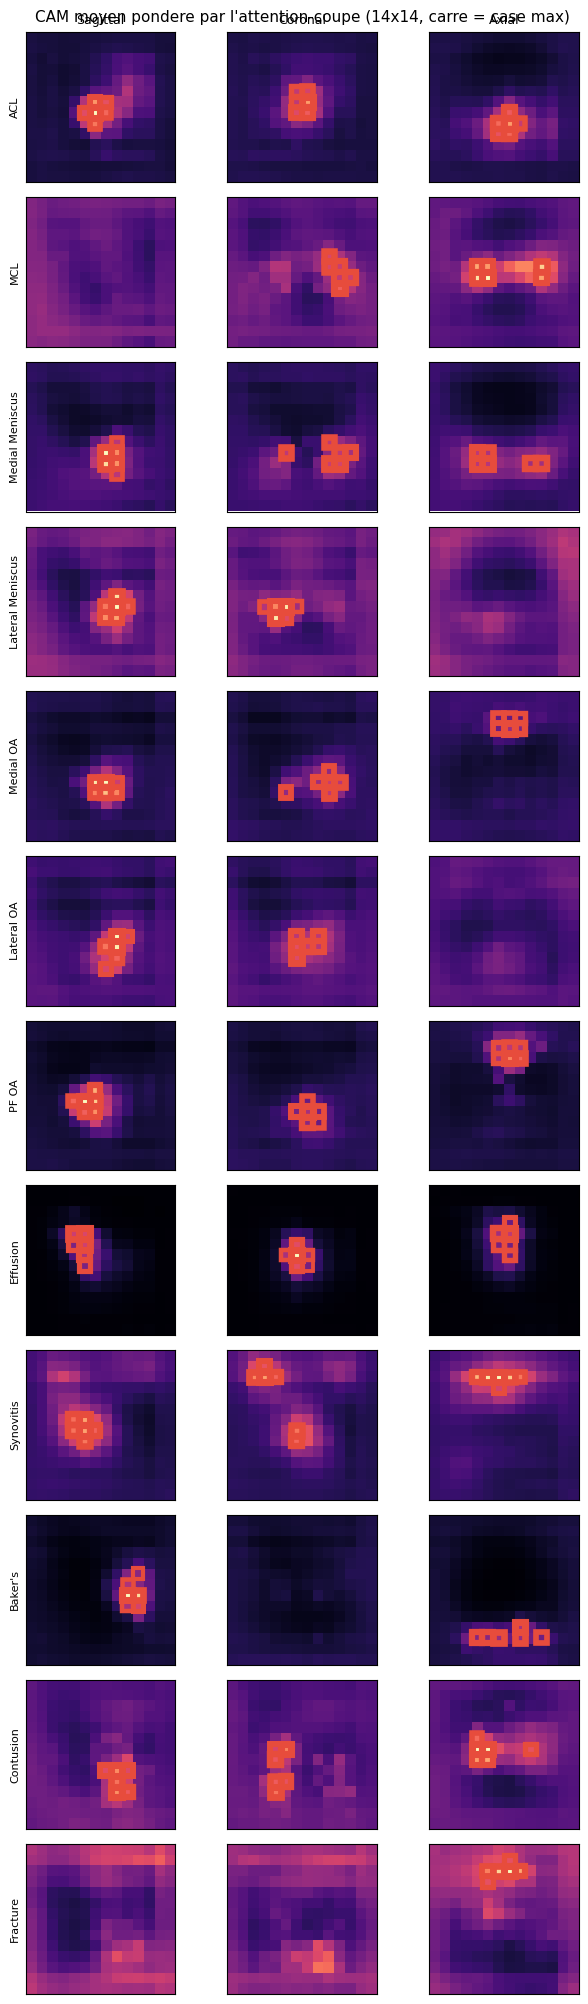

In [28]:
fig = plot_mean_cams(agg)
display(fig)
plt.close(fig)

## Top coupes + heatmap CAM

Une ligne : la coupe IRM, avec la **heatmap** du softmax spatial (jet, upsample bilinear 14×14 → 224). Rouge = case la plus pesée. Voile plat = tête encore diffuse.

On priorise les **gold positifs**. Fracture / contusion / Baker / ACL / épanchement.


5 overlays c:\Users\sulta\Documents\RSNA-comp\checkpoints\v17_crop130v1\spatial_inspect\overlays
top_ACL.png


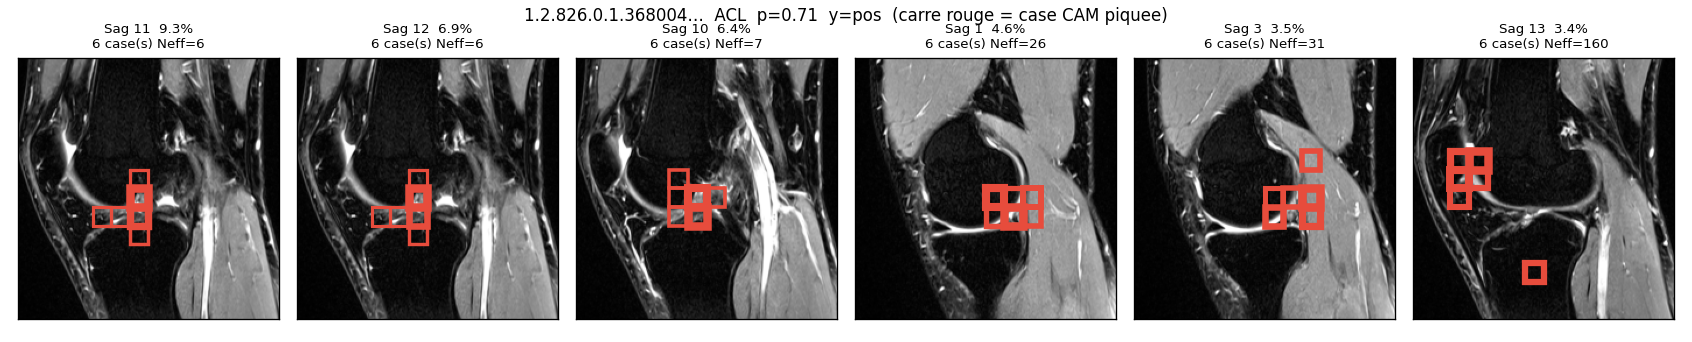

top_Bakers.png


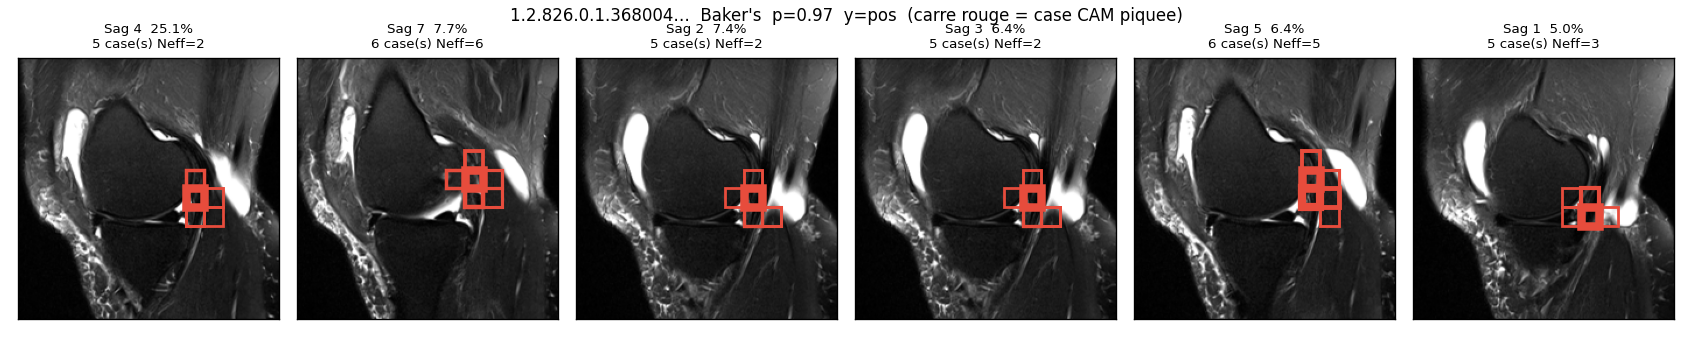

top_Contusion.png


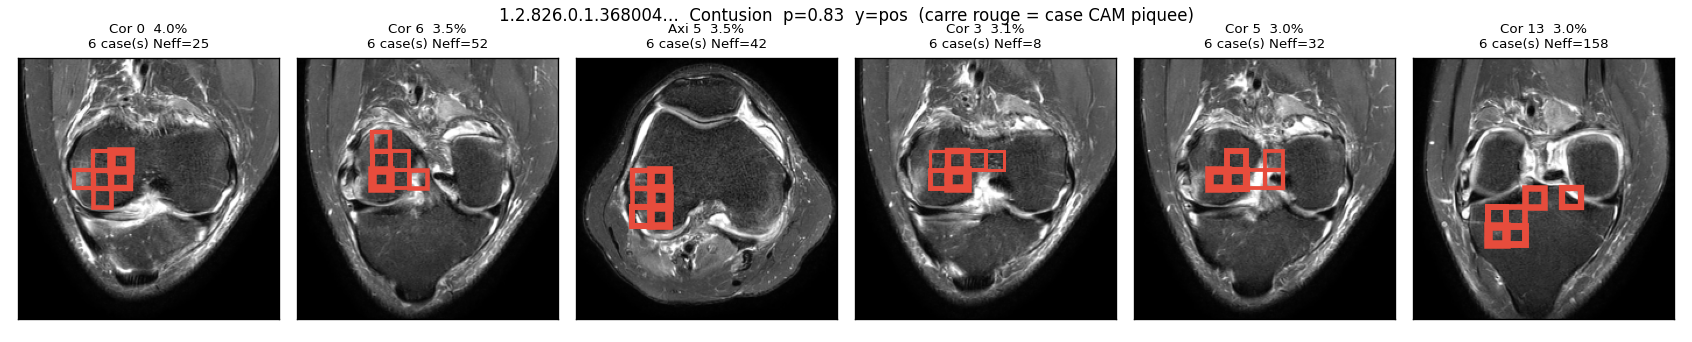

top_Effusion.png


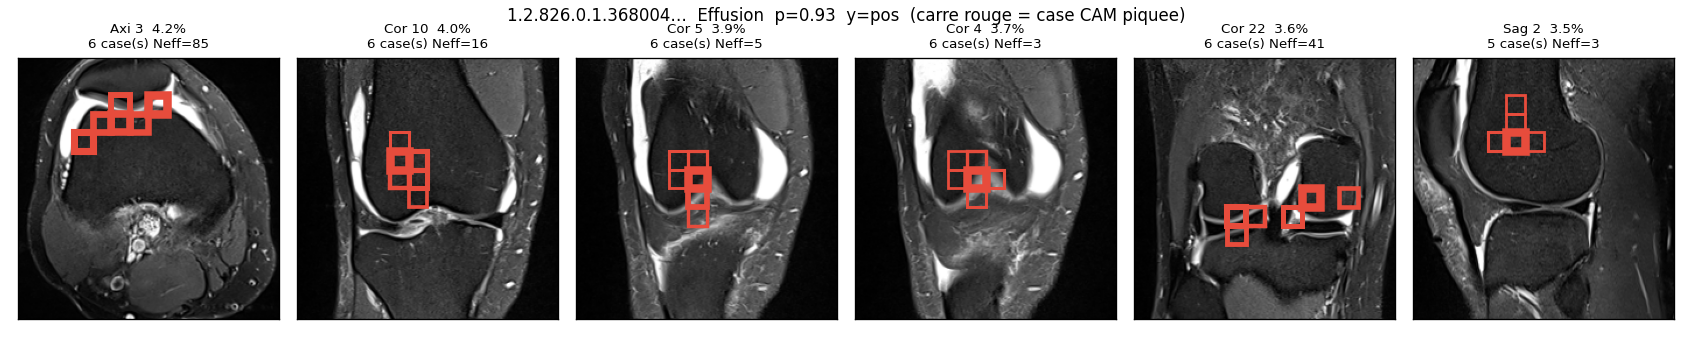

top_Fracture.png


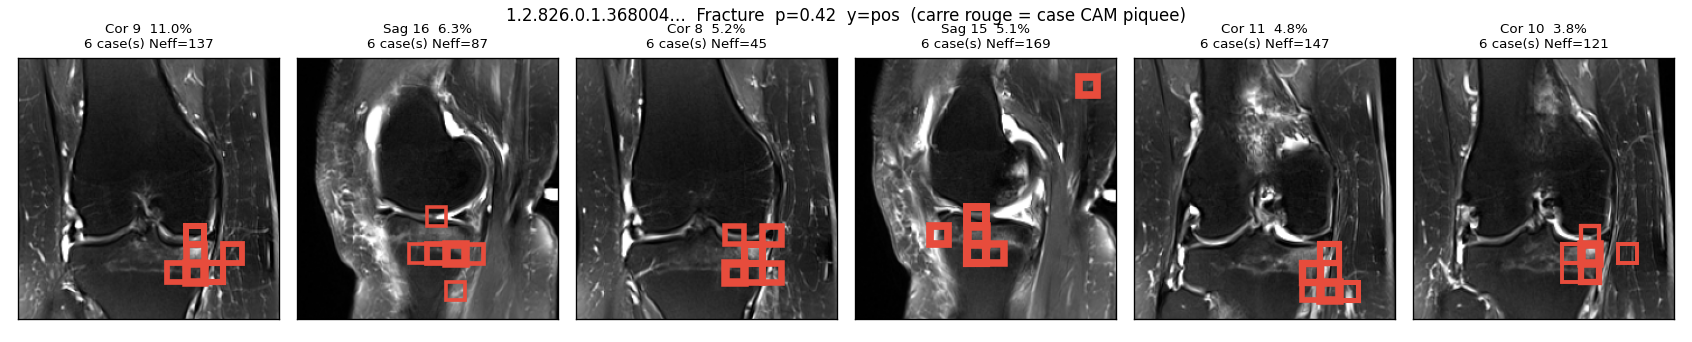

In [29]:
SHOW = ["ACL", "Baker's", "Contusion", "Fracture", "Effusion"]
planes = agg["planes"]
targets = agg["targets"]
ov = OUT / "overlays"

live = bool(agg.get("examples") or any(agg.get("pos_examples", {}).values()))
if live:
    for name in SHOW:
        if name not in targets:
            continue
        pool = agg["pos_examples"].get(name) or agg["examples"]
        if not pool:
            print(name, ": aucun exemple")
            continue
        fig = plot_top_slices(pool[0], name, targets, planes, k=6)
        display(fig)
        plt.close(fig)
else:
    files = sorted(ov.glob("top_*.png")) if ov.exists() else []
    print(len(files), "overlays", ov)
    for p in files:
        print(p.name)
        display(Image(filename=str(p)))


## Même coupe, têtes différentes

Coupe max pour ACL, puis les heatmaps de ACL / Baker / fracture. Si les trois blobent au même endroit, le spatial n’est pas spécifique. S’ils divergent (échancrure vs poplité vs bord), le 14×14 fait ce pour quoi v16/v17 ont été conçus.


3 meme-coupe c:\Users\sulta\Documents\RSNA-comp\checkpoints\v17_crop130v1\spatial_inspect\overlays
same_ex0.png


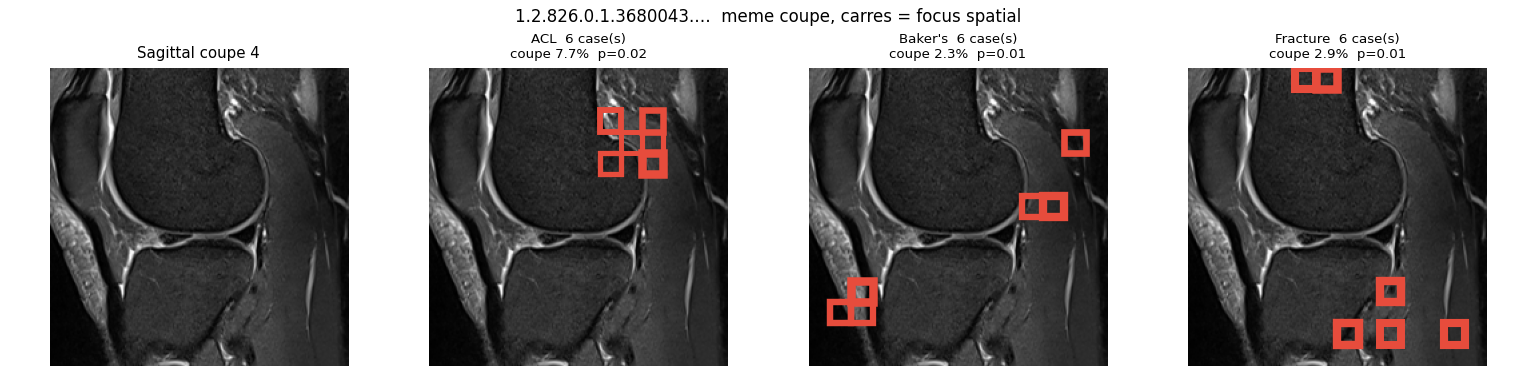

same_ex1.png


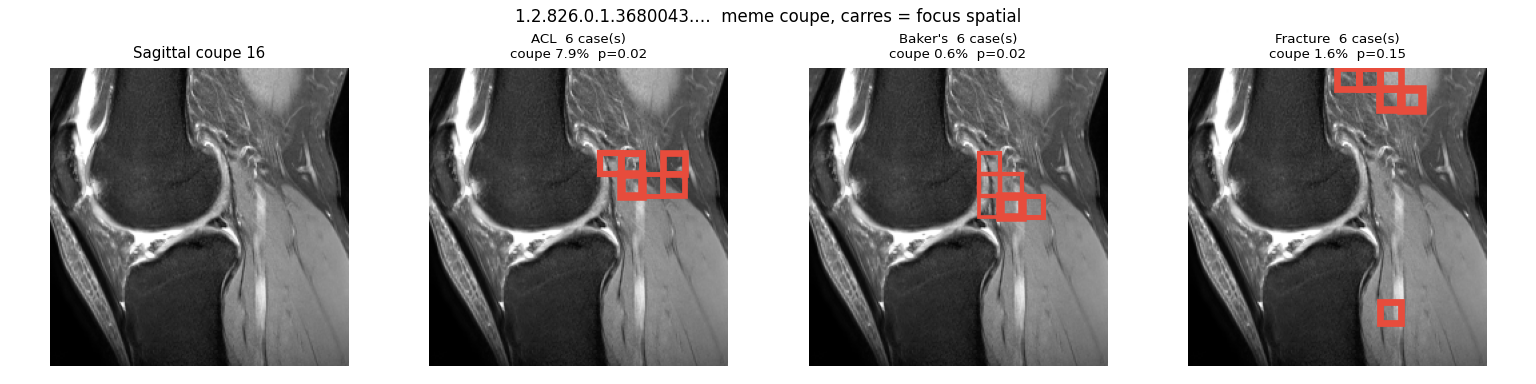

same_ex2.png


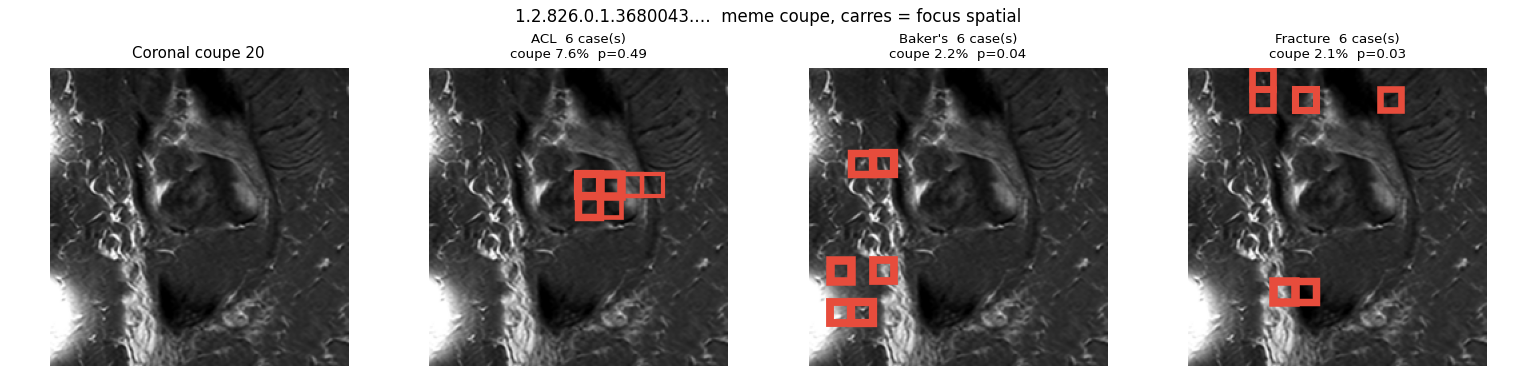

In [30]:
ov = OUT / "overlays"
if agg.get("examples"):
    n_show = min(3, len(agg["examples"]))
    for ex in agg["examples"][:n_show]:
        fig = plot_same_slice(ex, agg["targets"], agg["planes"])
        display(fig)
        plt.close(fig)
else:
    files = sorted(ov.glob("same_ex*.png")) if ov.exists() else []
    print(len(files), "meme-coupe", ov)
    for p in files:
        print(p.name)
        display(Image(filename=str(p)))


## Lecture (gold 58, v17 full epoch 12)

Le pooling spatial **n’est plus un collapse 7×7**. Sur la grille 14×14 (uniforme Neff 196), **11/12 têtes sont « un peu piquées »** et **une seule est vraiment piquée**.

| Têtes | Neff | max case | Lecture |
|---|---|---|---|
| Épanchement | 27 | 25 % | **Piqué** — ~une poignée de cases 14×14, pic central coronal (6,6) |
| Baker, PF OA | 84 | 10–11 % | Un peu piqué, plausible |
| ACL, OA médial | 95–104 | 7–9 % | Léger, plus net qu’en v14 (ACL y était encore GAP) |
| Ménisques, contusion, MCL, fracture, OA latéral, synovite | 110–133 | 4–7 % | Encore proche d’un GAP |

**0/12 têtes GAP-like** au seuil 0,70×196 (Neff>137). Inversion vs v14 subset : fracture / contusion **ne collent plus au bord du FOV** (argmax internes). Le 14×14 a dilué le raccourci 1-case ; l’épanchement a pris le rôle de tête localisée.

Le CAM moyen est **central** (cases ~7,6), pas un blob en bas de grille. Sur les overlays : si la heatmap est **sur le liquide / l’échancrure / le poplité** c’est du signal ; si elle colle **à l’air / au FOV** c’est encore un raccourci — moins fréquent qu’en v14.

## Suite

1. **Ne pas** resserrer `BAND` ni dropper 21–23 (notebook 10) : pas de coupe morte, et le spatial interne n’a plus besoin des bords comme béquille.
2. **Épanchement piqué** : vérifier les overlays. Heatmap sur l’épanchement supra-patellaire → le 14×14 sert ; blob sur un coin → pénalité d’entropie.
3. ACL / ménisques / OA restent **tièdes** (Neff 95–133). Le LSTM + 14×14 n’a pas transformé ces têtes en CAM focal. Autre levier (labels, T1) si on vise ces cibles.
4. Ablation utile : geler `spatial_score` à 0 (v17 = GAP 14×14 + LSTM) vs appris, pour chiffrer le gain réel du pooling spatial maintenant que le collapse fracture a disparu.
